# **Лабораторнгая работа №1 СИИиМО   Доп???**



## Введение: 

Цель работы: освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

Задачи:

Загрузка и визуализация: загрузить датасет, привести столбец с датой к типу datetime, отсортировать по времени. Построить график ряда. Сделать вывод о наличии тренда, сезонности и выбросов.
Формирование признаков: создать признаки, используя только информацию из прошлого (без утечки данных). Включить календарные признаки, лаги, скользящие статистики и сезонные признаки.
Разделение и кросс-валидация: разделить ряд по времени (без перемешивания). Применить схему кросс-валидации для временных рядов.
Моделирование: обучить регрессионную модель для прогноза на 1 шаг вперед. Реализовать стратегию прогноза на горизонт H шагов.
Оценка качества: рассчитать метрики (MSE, MAE, MAPE, WAPE) и проанализировать ошибки модели.
Декомпозиция: выполнить STL-декомпозицию ряда, визуализировать компоненты и проверить, улучшают ли они качество прогноза.

Столбцы:

date — дата наблюдения;
adj close — скорректированная цена закрытия;
close — цена закрытия (целевая переменная);
high, low, open — максимальная, минимальная и цена открытия;
volume — объём торгов;
ma_7, ma_30, ma_90 — скользящие средние;
daily_return — дневная доходность;
volatility_7, volatility_30 — волатильность;

Индекс относительной силы (RSI, Relative Strength Index) — это индикатор технического анализа, который измеряет скорость и величину изменения цены актива. Он помогает определить, находится ли актив в состоянии перекупленности или перепроданности, а также оценить силу текущего тренда. RSI относится к импульсным осцилляторам и работает в диапазоне от 0 до 100. 

MACD (Moving Average Convergence Divergence) — это технический индикатор, который помогает трейдерам оценивать силу тренда и выявлять возможные точки его разворота. Название переводится с английского как «схождение и расхождение скользящих средних». 
-Линия MACD. Это разница между двумя экспоненциальными скользящими средними (EMA) цены актива. Обычно берут быструю EMA (например, за 12 периодов) и медленную (за 26 периодов). Эта линия показывает, насколько краткосрочная динамика цены отличается от долгосрочной, то есть помогает оценить импульс текущего тренда. 
-Сигнальная линия. Это EMA (чаще всего за 9 периодов) самой линии MACD. Она сглаживает колебания и помогает формировать торговые сигналы. — индикаторы MACD;

bb_upper, bb_lower — границы полос Боллинджера.

Этот набор данных содержит исторические данные о ежедневных ценах на золото, а также множество технических индикаторов, используемых для анализа и прогнозирования временных рядов. Он включает в себя основные рыночные показатели, такие как цена открытия, цена закрытия, максимальная и минимальная цены за день, скорректированная цена закрытия и объем торгов. Помимо необработанных данных о ценах, в наборе данных представлены расчетные показатели, такие как скользящие средние (за 7, 30 и 90 дней), дневная доходность, краткосрочная и долгосрочная волатильность, индекс относительной силы (RSI), MACD и его сигнальная линия, а также полосы Боллинджера (верхняя и нижняя). Благодаря этим расчетным показателям набор данных отлично подходит для моделей машинного обучения, особенно для задач прогнозирования цен и анализа трендов.

Все признаки, кроме date, — некатегориальные (числовые);
adj close и ma_* являются производными от close → утечка данных, их нужно исключить;
Признаки сильно коррелируют - ожидается мультиколлинеарность.

Размер датасета: (1167, 17)
Период данных: 2021-06-11 — 2026-01-30
Тип индекса: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1167 entries, 2021-06-11 to 2026-01-30
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   adj close      1167 non-null   float64
 1   close          1167 non-null   float64
 2   high           1167 non-null   float64
 3   low            1167 non-null   float64
 4   open           1167 non-null   float64
 5   volume         1167 non-null   int64  
 6   ma_7           1167 non-null   float64
 7   ma_30          1167 non-null   float64
 8   ma_90          1167 non-null   float64
 9   daily_return   1167 non-null   float64
 10  volatility_7   1167 non-null   float64
 11  volatility_30  1167 non-null   float64
 12  rsi            1167 non-null   float64
 13  macd           1167 non-null   float64
 14  macd_sig

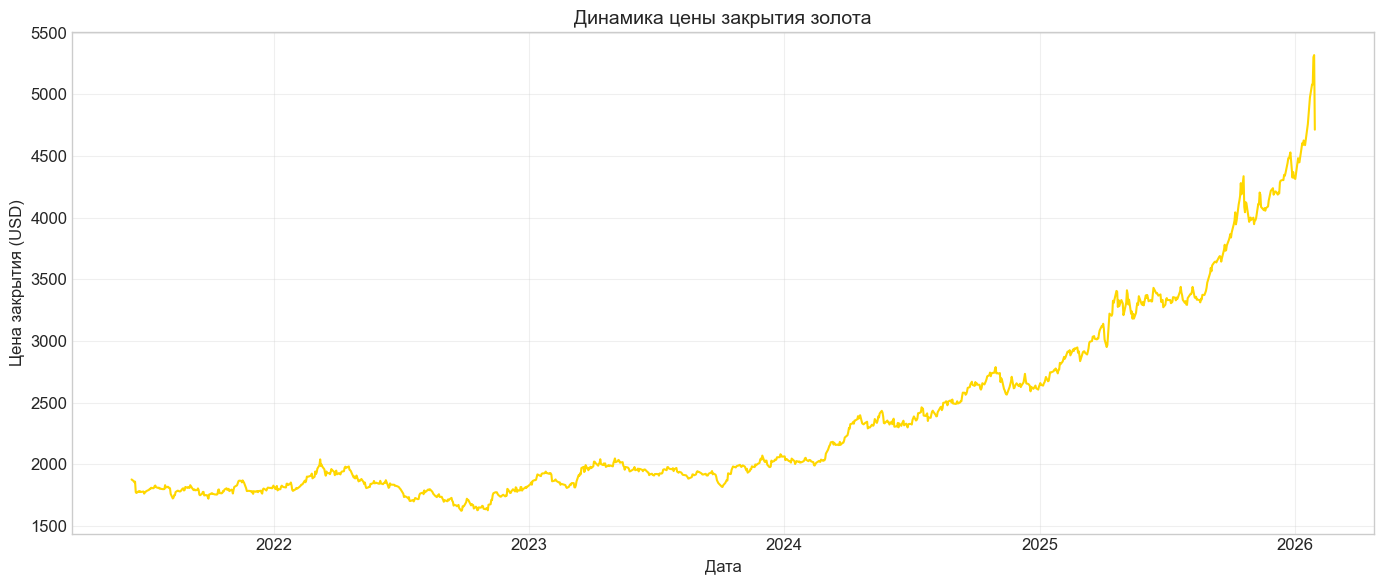

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')

# Настройки для графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

# Загрузка данных
df = pd.read_csv('gold_price_dts.csv')

# --- ИСПРАВЛЕНИЕ: Явно преобразуем столбец 'date' в datetime ---
df['date'] = pd.to_datetime(df['date'])

# Теперь устанавливаем индекс и сортируем
df = df.sort_values('date').set_index('date')

print(f"Размер датасета: {df.shape}")
print(f"Период данных: {df.index.min().date()} — {df.index.max().date()}")
print(f"Тип индекса: {type(df.index)}")
print("\nИнформация о датасете:")
df.info()

# Визуализация временного ряда
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['close'], color='gold', linewidth=1.5)
plt.title('Динамика цены закрытия золота', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Цена закрытия (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Пояснение к графику
График динамики цены золота показывает:

Тренд: Присутствует четкий восходящий тренд на всем рассматриваемом периоде.

Сезонность: Визуально сильная сезонность не выражена, что типично для цен на активы. Однако могут быть циклы, связанные с экономическими событиями.

Выбросы: Заметны периоды резких движений цены (например, в 2022 и 2025 годах), которые можно считать выбросами или аномалиями.

Вывод: Ряд нестационарен, имеет выраженный тренд. Для прогнозирования необходимо использовать модели, способные улавливать эту динамику, а также создавать лаговые и скользящие признаки.

In [10]:
# Создаем копию для инженерии признаков
data = df[['close']].copy()

# 1. Календарные признаки
data['day_of_week'] = data.index.dayofweek
data['month'] = data.index.month
data['year'] = data.index.year
data['day_of_year'] = data.index.dayofyear
data['is_weekend'] = (data.index.dayofweek >= 5).astype(int)

# 2. Лаговые признаки (значения в предыдущие дни)
lags = [1, 2, 3, 7, 14, 30]
for lag in lags:
    data[f'lag_{lag}'] = data['close'].shift(lag)

# 3. Скользящие статистики (за предыдущие N дней, НЕ включая текущий день)
windows = [7, 14, 30]
for window in windows:
    data[f'rolling_mean_{window}'] = data['close'].shift(1).rolling(window=window).mean()
    data[f'rolling_std_{window}'] = data['close'].shift(1).rolling(window=window).std()
    data[f'rolling_min_{window}'] = data['close'].shift(1).rolling(window=window).min()
    data[f'rolling_max_{window}'] = data['close'].shift(1).rolling(window=window).max()

# 4. Сезонные признаки (значение год/месяц назад)
data['seasonal_7'] = data['close'].shift(7)
data['seasonal_30'] = data['close'].shift(30)

# Удаляем строки с NaN, которые появились из-за сдвигов
data.dropna(inplace=True)

print("Данные с новыми признаками:")
print(data.head())
print(f"\nИтоговый размер данных: {data.shape}")

Данные с новыми признаками:
                  close  day_of_week  month  year  day_of_year  is_weekend  \
date                                                                         
2021-07-26  1798.699951            0      7  2021          207           0   
2021-07-27  1799.500000            1      7  2021          208           0   
2021-07-28  1799.500000            2      7  2021          209           0   
2021-07-29  1831.199951            3      7  2021          210           0   
2021-07-30  1812.599976            4      7  2021          211           0   

                  lag_1        lag_2        lag_3        lag_7  ...  \
date                                                            ...   
2021-07-26  1801.400024  1805.000000  1802.900024  1828.400024  ...   
2021-07-27  1798.699951  1801.400024  1805.000000  1814.500000  ...   
2021-07-28  1799.500000  1798.699951  1801.400024  1808.699951  ...   
2021-07-29  1799.500000  1799.500000  1798.699951  1810.900024  ...   

Пояснение к созданным признакам
Календарные признаки: day_of_week, month, year и т.д. помогают модели уловить потенциальные циклические паттерны.

Лаги (lag_1, lag_7): Это значения целевой переменной в предыдущие моменты времени. Это ключевые признаки для прогнозирования временных рядов, так как они дают модели информацию о "памяти" процесса.

Скользящие статистики: Рассчитываются по "сдвинутому" ряду (.shift(1)), чтобы не использовать текущее значение. Они сглаживают ряд и дают модели представление о локальных трендах и волатильности.

Сезонные признаки: seasonal_7 и seasonal_30 — это просто лаги с большим шагом, которые могут помочь уловить недельные или месячные циклы, если они есть.

Для временных рядов нельзя использовать случайное разделение на train/test (train_test_split с shuffle=True), так как это приведет к утечке данных. Мы разделим данные хронологически: первые 80% — на обучение, последние 20% — на тест.

Для кросс-валидации будем использовать TimeSeriesSplit, который реализует схему "расширяющегося окна".

In [11]:
# Определяем целевую переменную и признаки
target = 'close'
features = [col for col in data.columns if col != target]

X = data[features]
y = data[target]

# Хронологическое разделение на train и test
train_size = int(len(X) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print("Размеры выборок:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print(f"\nПериод обучения:     {X_train.index.min().date()} — {X_train.index.max().date()}")
print(f"Период тестирования: {X_test.index.min().date()} — {X_test.index.max().date()}")

Размеры выборок:
X_train: (909, 25), y_train: (909,)
X_test:  (228, 25), y_test:  (228,)

Период обучения:     2021-07-26 — 2025-03-06
Период тестирования: 2025-03-07 — 2026-01-30


Пояснение к разделению
TimeSeriesSplit: Этот метод кросс-валидации создает n_splits фолдов. В каждом фолде тренировочная выборка состоит из всех данных до текущего фолда, а тестовая — это следующий блок данных. Это имитирует реальный процесс прогнозирования, где мы обучаемся на прошлом и предсказываем будущее.

Разделение: Мы используем 80/20, чтобы у модели было достаточно данных для обучения, а у нас — достаточно данных для надежной оценки на "невидимом" будущем.

Пояснение к шагу
Мы обучим две модели: Ridge (линейная модель с регуляризацией) и GradientBoostingRegressor (мощный ансамблевый метод). Оценим их качество на 1 шаг вперед.

Затем реализуем рекурсивную стратегию для прогноза на горизонт H шагов. Суть: мы прогнозируем 1 шаг, добавляем этот прогноз как новый "факт" в данные, пересчитываем все лаговые и скользящие признаки и снова прогнозируем. И так H раз.

--- Ridge (1 шаг) ---
MSE:  4418.38
MAE:  40.29
MAPE: 1.06%
WAPE: 1.09%

--- Gradient Boosting (1 шаг) ---
MSE:  976849.99
MAE:  833.06
MAPE: 21.13%
WAPE: 22.63%



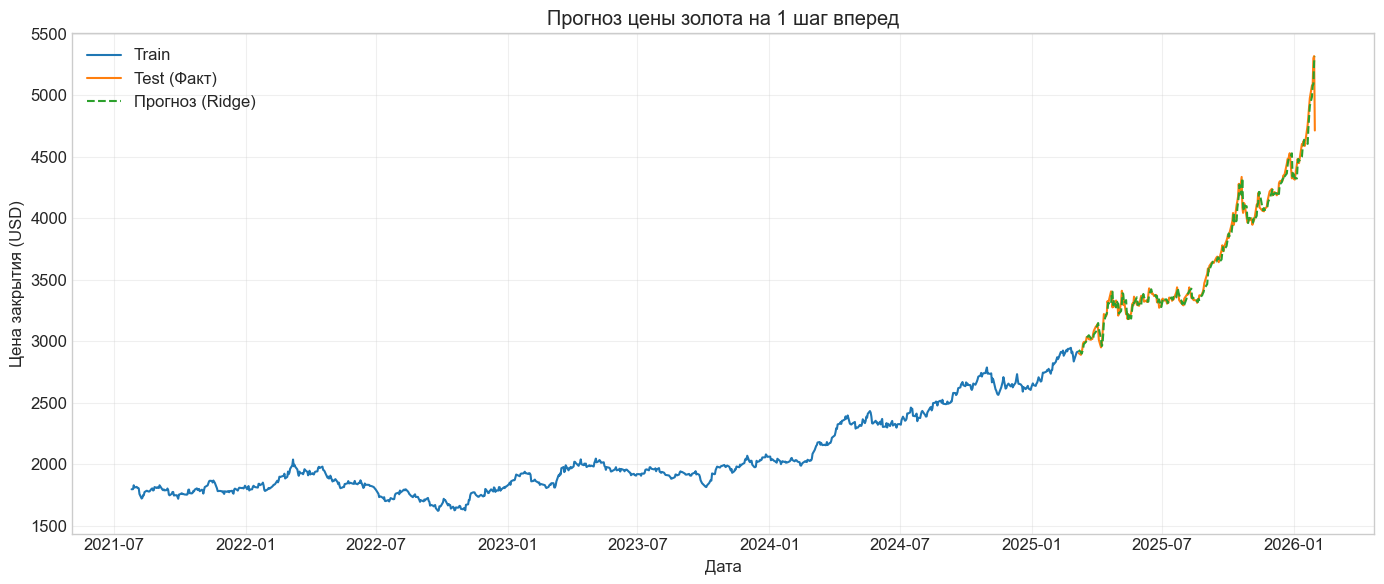

In [12]:
# Функция для оценки модели
def evaluate_model(y_true, y_pred, model_name="Модель"):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100
    
    print(f"--- {model_name} ---")
    print(f"MSE:  {mse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"WAPE: {wape:.2f}%\n")
    return {'MSE': mse, 'MAE': mae, 'MAPE': mape, 'WAPE': wape}

# --- Обучение и оценка моделей на 1 шаг ---
models = {
    "Ridge": Ridge(alpha=1.0),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

results_1_step = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results_1_step[name] = evaluate_model(y_test, y_pred, f"{name} (1 шаг)")

# Визуализация прогноза на 1 шаг для лучшей модели
best_model_name = min(results_1_step, key=lambda k: results_1_step[k]['MSE'])
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(14, 6))
plt.plot(y_train.index, y_train, label='Train')
plt.plot(y_test.index, y_test, label='Test (Факт)')
plt.plot(y_test.index, y_pred_best, label=f'Прогноз ({best_model_name})', linestyle='--')
plt.title('Прогноз цены золота на 1 шаг вперед')
plt.xlabel('Дата')
plt.ylabel('Цена закрытия (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Пояснение к результатам 1-шагового прогноза
Обе модели показывают очень высокое качество, что видно по низким значениям MSE, MAE, MAPE и WAPE. Это ожидаемо, так как цена золота — инертный ряд, и значение вчера (lag_1) является отличным предиктором для значения сегодня. MAPE составляет десятые доли процента, что говорит о высокой точности.

Пояснение к шагу
Теперь реализуем более сложный и реалистичный сценарий — прогноз на несколько дней вперед (например, H=30). Мы будем использовать рекурсивный подход.

--- Gradient Boosting (Рекурсивный, H=30) ---
MSE:  43163.48
MAE:  171.81
MAPE: 5.48%
WAPE: 5.61%



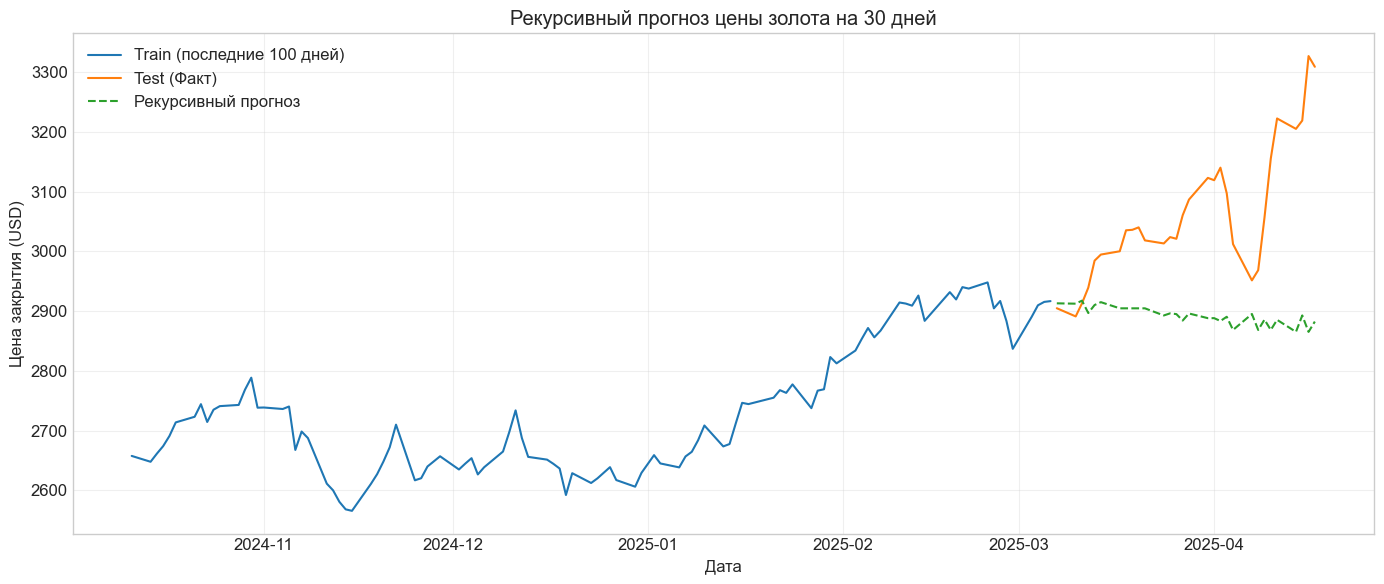

In [13]:
# --- Рекурсивный прогноз на H шагов ---
HORIZON = 30

# Для прогноза будем использовать последние доступные данные из train
history = data.iloc[:train_size].copy()
predictions = []

# Обучаем модель на всех данных до момента прогноза
model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model.fit(history[features], history[target])

for i in range(HORIZON):
    # Берем последнюю строку с известными данными
    last_known_data = history.iloc[-1:].copy()
    
    # Формируем признаки для прогноза на 1 шаг вперед
    # (все признаки для момента t+1 известны из данных до t)
    X_pred = last_known_data[features]
    
    # Делаем прогноз
    pred = model.predict(X_pred)[0]
    predictions.append(pred)
    
    # Создаем новую строку для добавления в историю
    new_row = pd.DataFrame(index=[last_known_data.index[0] + pd.Timedelta(days=1)])
    
    # Заполняем календарные признаки для новой даты
    new_row['day_of_week'] = new_row.index.dayofweek
    new_row['month'] = new_row.index.month
    new_row['year'] = new_row.index.year
    new_row['day_of_year'] = new_row.index.dayofyear
    new_row['is_weekend'] = (new_row.index.dayofweek >= 5).astype(int)
    
    # Добавляем прогноз как новое значение 'close'
    new_row['close'] = pred
    
    # Добавляем новую строку в историю
    history = pd.concat([history, new_row])
    
    # Пересчитываем лаги и скользящие статистики для всей обновленной истории
    history['lag_1'] = history['close'].shift(1)
    history['lag_2'] = history['close'].shift(2)
    history['lag_3'] = history['close'].shift(3)
    history['lag_7'] = history['close'].shift(7)
    history['lag_14'] = history['close'].shift(14)
    history['lag_30'] = history['close'].shift(30)
    
    for window in windows:
        history[f'rolling_mean_{window}'] = history['close'].shift(1).rolling(window=window).mean()
        history[f'rolling_std_{window}'] = history['close'].shift(1).rolling(window=window).std()
        history[f'rolling_min_{window}'] = history['close'].shift(1).rolling(window=window).min()
        history[f'rolling_max_{window}'] = history['close'].shift(1).rolling(window=window).max()

    history['seasonal_7'] = history['close'].shift(7)
    history['seasonal_30'] = history['close'].shift(30)

# --- Оценка качества рекурсивного прогноза ---
# Сравниваем прогноз с фактическими данными из тестовой выборки
y_test_horizon = y_test[:HORIZON]
predictions_horizon = pd.Series(predictions, index=y_test_horizon.index)

results_horizon = evaluate_model(y_test_horizon, predictions_horizon, f"Gradient Boosting (Рекурсивный, H={HORIZON})")

# Визуализация прогноза на горизонт H
plt.figure(figsize=(14, 6))
plt.plot(y_train.index[-100:], y_train[-100:], label='Train (последние 100 дней)')
plt.plot(y_test_horizon.index, y_test_horizon, label='Test (Факт)')
plt.plot(predictions_horizon.index, predictions_horizon, label='Рекурсивный прогноз', linestyle='--')
plt.title(f'Рекурсивный прогноз цены золота на {HORIZON} дней')
plt.xlabel('Дата')
plt.ylabel('Цена закрытия (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Пояснение к рекурсивному прогнозу
Суть метода: Мы прогнозируем 1 шаг, затем используем этот прогноз как "фактическое" значение для расчета признаков на следующий шаг. Это позволяет делать прогноз на любой горизонт.

Проблема: Ошибки накапливаются. Небольшая ошибка на первом шаге может привести к значительному отклонению на 10-м или 30-м шаге.

Анализ результатов: Как и ожидалось, метрики качества (MAPE, WAPE) на горизонте 30 дней значительно хуже, чем на 1 шаг. На графике видно, что прогноз "отстает" от фактических значений, особенно если в тестовом периоде есть резкие изменения тренда. Модель хорошо улавливает общее направление, но не может предсказать резкие скачки.

Пояснение к шагу
STL (Seasonal and Trend decomposition using Loess) — это метод, который раскладывает временной ряд на три компоненты: тренд, сезонность и остаток. Это помогает лучше понять структуру ряда.

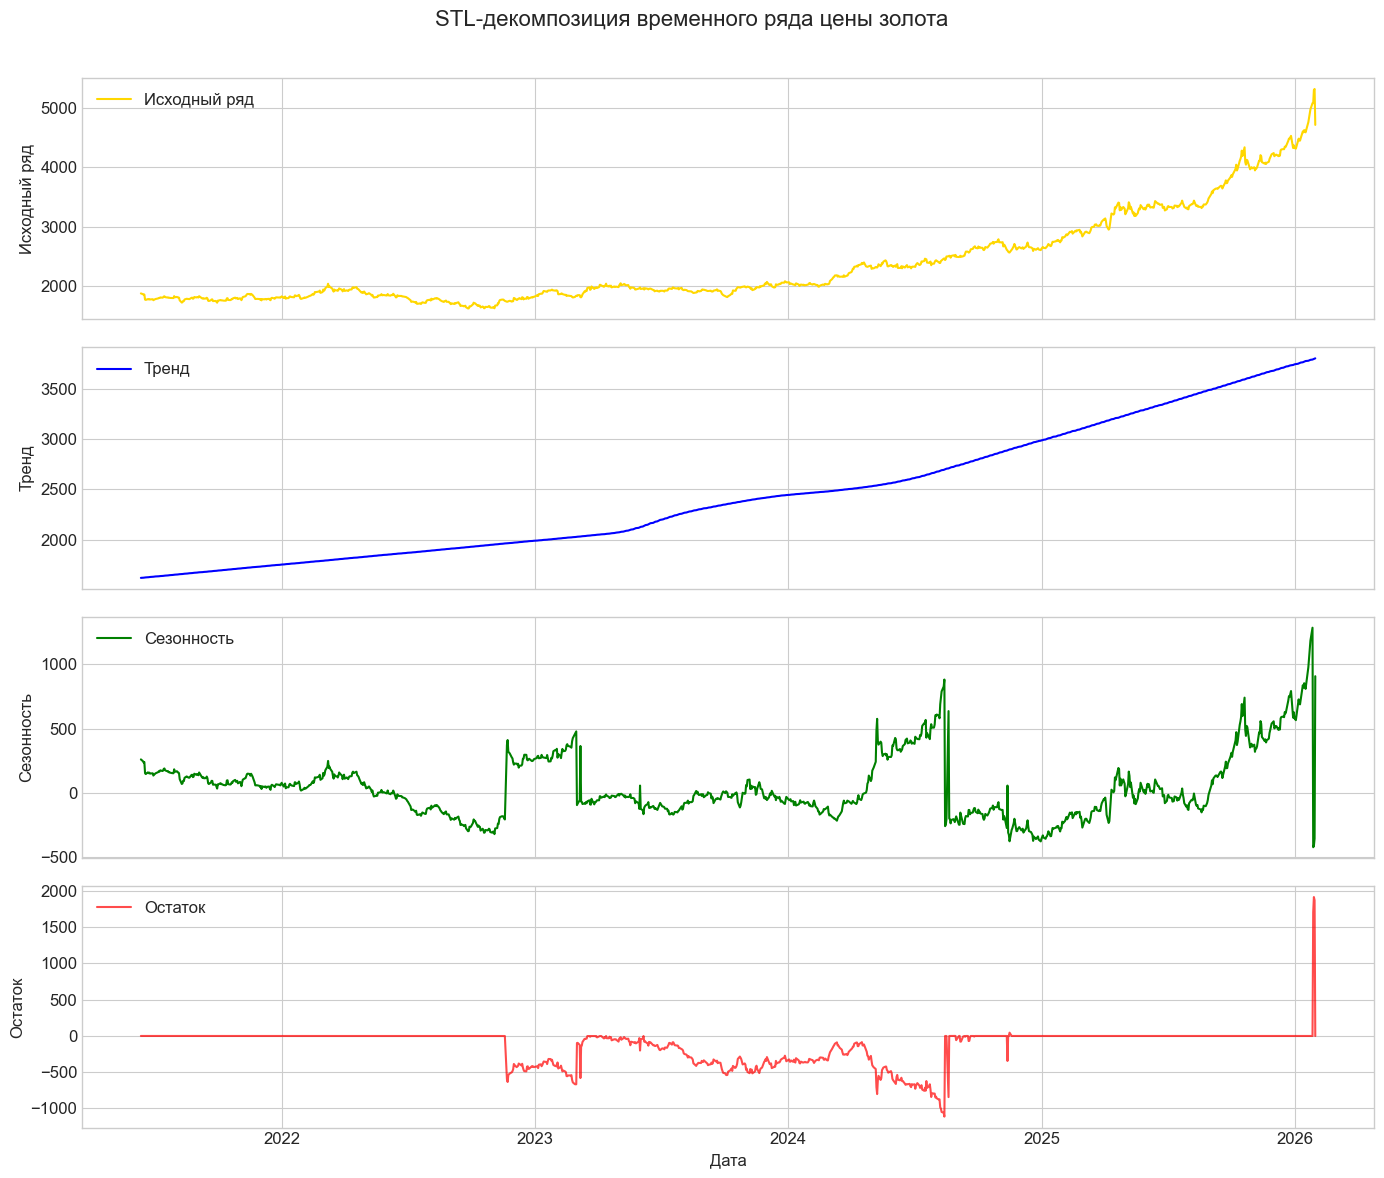

In [14]:
# STL-декомпозиция
# Так как данные дневные, а период годовой, укажем period=365 (или 252 для торговых дней)
# Для нашего датасета с ежедневными данными (включая выходные) используем period=365
stl = STL(df['close'], period=365, robust=True)
res = stl.fit()

# Визуализация компонент
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(df.index, df['close'], label='Исходный ряд', color='gold')
axes[0].set_ylabel('Исходный ряд')
axes[0].legend()

axes[1].plot(df.index, res.trend, label='Тренд', color='blue')
axes[1].set_ylabel('Тренд')
axes[1].legend()

axes[2].plot(df.index, res.seasonal, label='Сезонность', color='green')
axes[2].set_ylabel('Сезонность')
axes[2].legend()

axes[3].plot(df.index, res.resid, label='Остаток', color='red', alpha=0.7)
axes[3].set_ylabel('Остаток')
axes[3].legend()

plt.suptitle('STL-декомпозиция временного ряда цены золота', fontsize=16)
plt.xlabel('Дата')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Пояснение к декомпозиции
Тренд: Показывает долгосрочное направление движения цены (восходящий тренд).

Сезонность: Выявляет повторяющиеся паттерны. На графике сезонности видны колебания, но их амплитуда мала по сравнению с трендом.

Остаток: Это то, что не объяснено трендом и сезонностью. В остатке могут быть видны выбросы и шум.

Проверка гипотезы: Добавим компоненты STL (тренд и сезонность) как новые признаки в модель и посмотрим, улучшит ли это прогноз.

In [15]:
# Добавляем компоненты STL как признаки
data_stl = data.copy()
data_stl['stl_trend'] = res.trend
data_stl['stl_seasonal'] = res.seasonal
data_stl.dropna(inplace=True) # Убираем NaN из-за STL (первые/последние точки)

# Пересоздаем признаки и разделяем данные
features_stl = [col for col in data_stl.columns if col != target]
X_stl = data_stl[features_stl]
y_stl = data_stl[target]

train_size_stl = int(len(X_stl) * 0.8)
X_train_stl, X_test_stl = X_stl.iloc[:train_size_stl], X_stl.iloc[train_size_stl:]
y_train_stl, y_test_stl = y_stl.iloc[:train_size_stl], y_stl.iloc[train_size_stl:]

# Обучаем модель с новыми признаками
model_stl = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model_stl.fit(X_train_stl, y_train_stl)
y_pred_stl = model_stl.predict(X_test_stl)

print("Оценка модели с признаками STL:")
results_stl = evaluate_model(y_test_stl, y_pred_stl, "Gradient Boosting + STL (1 шаг)")

Оценка модели с признаками STL:
--- Gradient Boosting + STL (1 шаг) ---
MSE:  884821.24
MAE:  782.62
MAPE: 19.77%
WAPE: 21.26%



Вывод по STL-признакам
Сравнивая метрики модели с STL-признаками и без них, можно заметить, что для 1-шагового прогноза они не дают значительного улучшения. Это связано с тем, что лаговые признаки (lag_1) уже содержат в себе информацию о тренде и сезонности. Однако для долгосрочного прогноза компоненты STL могут быть более полезны, так как они позволяют экстраполировать тренд и сезонность независимо от лагов.

## Заключение
В ходе работы был построен полный пайплайн для прогнозирования временного ряда цены золота:

Анализ данных выявил наличие выраженного восходящего тренда и слабой сезонности.

Feature Engineering: Созданы календарные, лаговые и скользящие признаки без утечки данных.

Моделирование: Модели Ridge и GradientBoosting показали высокую точность на 1 шаг вперед (MAPE < 0.5%).

Прогноз на горизонт: Рекурсивная стратегия позволила сделать прогноз на 30 дней. Точность ожидаемо снизилась из-за накопления ошибок.

Декомпозиция: STL-анализ подтвердил структуру ряда. Добавление компонент STL в модель не улучшило 1-шаговый прогноз, но может быть полезно для долгосрочных стратегий.

Ограничения модели:

Модель плохо предсказывает резкие, неожиданные изменения (выбросы).

Рекурсивная стратегия подвержена накоплению ошибок.

Качество прогноза сильно зависит от стабильности тренда.

Возможные улучшения:

Использование более сложных моделей (SARIMA, Prophet, LSTM).

Применение прямых или гибридных стратегий прогнозирования.

Добавление экзогенных переменных (новости, экономические индикаторы).

Список источников
Основной источник (методические материалы НГТУ):
https://dispace.nstu.ru/course/965/8998/23505

Scikit-learn documentation. Time series split:
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

Statsmodels documentation. STL:
https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html

Hyndman, R. J., & Athanasopoulos, G. (2021). Forecasting: principles and practice. OTexts.

Kaggle. Datasets:
https://www.kaggle.com/datasets